# Heart Sound Analysis -- Automated Benchmark & Audit Pipeline
### Leakage-Aware Evaluation, 5 Architectural Ablations, Explanation Audits & Paper Deliverables

**Instructions:**
1. Go to **Runtime -> Change runtime type** and ensure **T4 GPU** is selected.
2. Click **Runtime -> Run all** (or press `Ctrl + F9`).
3. The notebook will automatically execute the entire 24-experiment benchmark, audit explanation faithfulness, compile all LaTeX tables and macros, and download the results.


## 0. Environment Setup & GPU Verification

In [1]:
# Check GPU availability (CUDA or Apple Silicon MPS)
import sys
import shutil
import torch

print(f'PyTorch Version: {torch.__version__}')
cuda_avail = torch.cuda.is_available()
mps_avail = hasattr(torch.backends, 'mps') and torch.backends.mps.is_available()
print(f'CUDA Available: {cuda_avail}')
print(f'Apple Silicon MPS Available: {mps_avail}')

if cuda_avail:
    print(f'GPU Device: {torch.cuda.get_device_name(0)}')
    print(f'VRAM: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB')
    if shutil.which('nvidia-smi'):
        !nvidia-smi
elif mps_avail:
    print('Using Apple Silicon Metal Performance Shaders (MPS) GPU acceleration.')
else:
    print('Running on CPU.')


PyTorch Version: 2.14.1
CUDA Available: False
Apple Silicon MPS Available: True
Using Apple Silicon Metal Performance Shaders (MPS) GPU acceleration.


In [2]:
# Install required Python dependencies
%pip install -q librosa scipy numpy pandas torch torchvision tqdm shap h5py pytest

/Users/urvagandhi/Developer/College/heart-sound-analysis/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


## 1. Repository Setup & Drive Mount (Optional)

In [3]:
import os
from pathlib import Path

# 1. Mount Google Drive if running in Colab (browser or VS Code Colab extension)
if os.path.exists('/content'):
    if not Path('/content/drive/MyDrive').exists():
        from google.colab import drive
        drive.mount('/content/drive')
    print('Google Drive mounted.')
    project_dir = Path('/content/drive/MyDrive/heart-sound-analysis')
else:
    print('Running locally on MacBook.')
    project_dir = Path.cwd()

# 2. Set active working directory directly to the project folder
os.chdir(str(project_dir))
print(f'Active working directory: {Path.cwd()}')

Running locally on MacBook.
Active working directory: /Users/urvagandhi/Developer/College/heart-sound-analysis


## 2. Dataset Verification & Extraction

In [4]:
from pathlib import Path

data_dir = Path("physionet_2016")
spec_dir = data_dir / "spectrograms"
meta_csv = data_dir / "metadata.csv"

num_specs = len(list(spec_dir.glob("*.npy"))) if spec_dir.exists() else 0
print(f"Spectrograms available : {num_specs} / 3541")
print(f"Metadata CSV exists    : {meta_csv.exists()}")
print(f"Dataset status         : {'READY' if num_specs >= 3541 and meta_csv.exists() else 'CHECK PATH'}")

Spectrograms available : 6781 / 3541
Metadata CSV exists    : True
Dataset status         : READY


## 3. Generate Splits & Run Duplicate Leakage Audit

In [5]:
# Generate deduplicated (3 seeds) and LODO splits
import sys
py_exec = sys.executable

!{py_exec} 'Review 3/make_splits.py' --mode dedup --seeds 42 43 44
!{py_exec} 'Review 3/make_splits.py' --mode lodo --holdouts a b e f --seed 42

# Check twin duplicate performance vs unique test accuracy
!{py_exec} 'Review 3/verify_duplicates.py'


Loaded 3541 rows from /Users/urvagandhi/Developer/College/heart-sound-analysis/physionet_2016/metadata.csv
Saved deduplicated metadata: /Users/urvagandhi/Developer/College/heart-sound-analysis/physionet_2016/metadata_dedup.csv (3240 rows)
  Saved dedup_seed42.json: Train=2268, Val=486, Test=486
  Saved dedup_seed43.json: Train=2268, Val=486, Test=486
  Saved dedup_seed44.json: Train=2268, Val=486, Test=486
Loaded 3541 rows from /Users/urvagandhi/Developer/College/heart-sound-analysis/physionet_2016/metadata.csv
  Saved lodo_holda_seed42.json: Holdout=a (409 test), Train=2406, Val=425
  Saved lodo_holdb_seed42.json: Holdout=b (490 test), Train=2337, Val=413
  Saved lodo_holde_seed42.json: Holdout=e (2141 test), Train=934, Val=165
  Saved lodo_holdf_seed42.json: Holdout=f (114 test), Train=2657, Val=469
Content verification status: UNVERIFIED by content
Leakage check saved to /Users/urvagandhi/Developer/College/heart-sound-analysis/results/leakage_check.json:
  Test rows: 532 total (70 t

## 4. Run All 24 Benchmark Experiments Sequentially

In [6]:
# Dry-run verification (24 planned runs)
import sys
py_exec = sys.executable
!{py_exec} 'Review 3/run_all.py' --dry-run

# Execute full 24-run benchmark (resume-safe: skips already completed runs)
!{py_exec} 'Review 3/run_all.py'


  Heart Sound Benchmark Runner (run_all.py)
  Total planned runs : 24
  Output root        : /Users/urvagandhi/Developer/College/heart-sound-analysis/results
  Dry run mode       : True
   1/24 [DONE] legacy_se_mha                    (variant=se_mha, split=legacy)
   2/24 [DONE] dedup_baseline_seed42            (variant=baseline, split=dedup)
   3/24 [DONE] dedup_baseline_seed43            (variant=baseline, split=dedup)
   4/24 [DONE] dedup_baseline_seed44            (variant=baseline, split=dedup)
   5/24 [DONE] dedup_se_seed42                  (variant=se, split=dedup)
   6/24 [DONE] dedup_se_seed43                  (variant=se, split=dedup)
   7/24 [DONE] dedup_se_seed44                  (variant=se, split=dedup)
   8/24 [DONE] dedup_mha_seed42                 (variant=mha, split=dedup)
   9/24 [DONE] dedup_mha_seed43                 (variant=mha, split=dedup)
  10/24 [DONE] dedup_mha_seed44                 (variant=mha, split=dedup)
  11/24 [DONE] dedup_se_mha_seed42              

## 5. Run Population-Level Explanation & Clinical Audit Suite

Execute the 5-component quantitative audit suite spanning:
1. **Calibration & Clinical Operating Point:** ECE calculation and sensitivity-targeted threshold calibration.
2. **Frequency Band Occlusion:** Evaluating acoustic reliance on B1 (20–150 Hz), B2 (150–500 Hz), and B3 (500–1000 Hz) against 20 row-matched random window controls.
3. **Faithfulness Deletion & Insertion Curves:** Area-Under-Curve perturbation tracking for Grad-CAM, Attention, and Gradient SHAP.
4. **Adebayo Cascading Weight Randomization Sanity Check:** Top-down network randomization to verify learned parameter dependence.
5. **Multi-Method Agreement & PhysioNet State Enrichment:** Quantifying spatial attribution alignment and S1/S2/systole/diastole cycle focus.

In [7]:
# 5.1 Run Audit on Top-Performing Model: dedup_se_seed42 (ResNet50 + SE Sweet Spot)
# Highest diagnostic accuracy (89.0% Balanced Acc, 95.4% AUC-ROC, 25.1M params)
import sys
py_exec = sys.executable
!{py_exec} "Review 3/audit/run_audit.py" --tag dedup_se_seed42 --shap-n 128

  Audit for 'dedup_se_seed42' is already complete!
  All 6 clinical audit artifacts and figures exist in: /Users/urvagandhi/Developer/College/heart-sound-analysis/results/audit_dedup_se_seed42
  Skipping audit execution (pass --force to re-run from scratch).


In [8]:
# 5.2 Run Audit on Reference Attention Model: dedup_se_mha_seed42 (ResNet50 + SE + MHSA)
# Investigates multi-head self-attention rollout and Grad-CAM/SHAP agreement (41.9M params)
import sys
py_exec = sys.executable
!{py_exec} "Review 3/audit/run_audit.py" --tag dedup_se_mha_seed42 --shap-n 128

  Audit for 'dedup_se_mha_seed42' is already complete!
  All 6 clinical audit artifacts and figures exist in: /Users/urvagandhi/Developer/College/heart-sound-analysis/results/audit_dedup_se_mha_seed42
  Skipping audit execution (pass --force to re-run from scratch).



  Explanation & Clinical Audit Visuals: dedup_se_seed42

[gradcam_overlays.png]


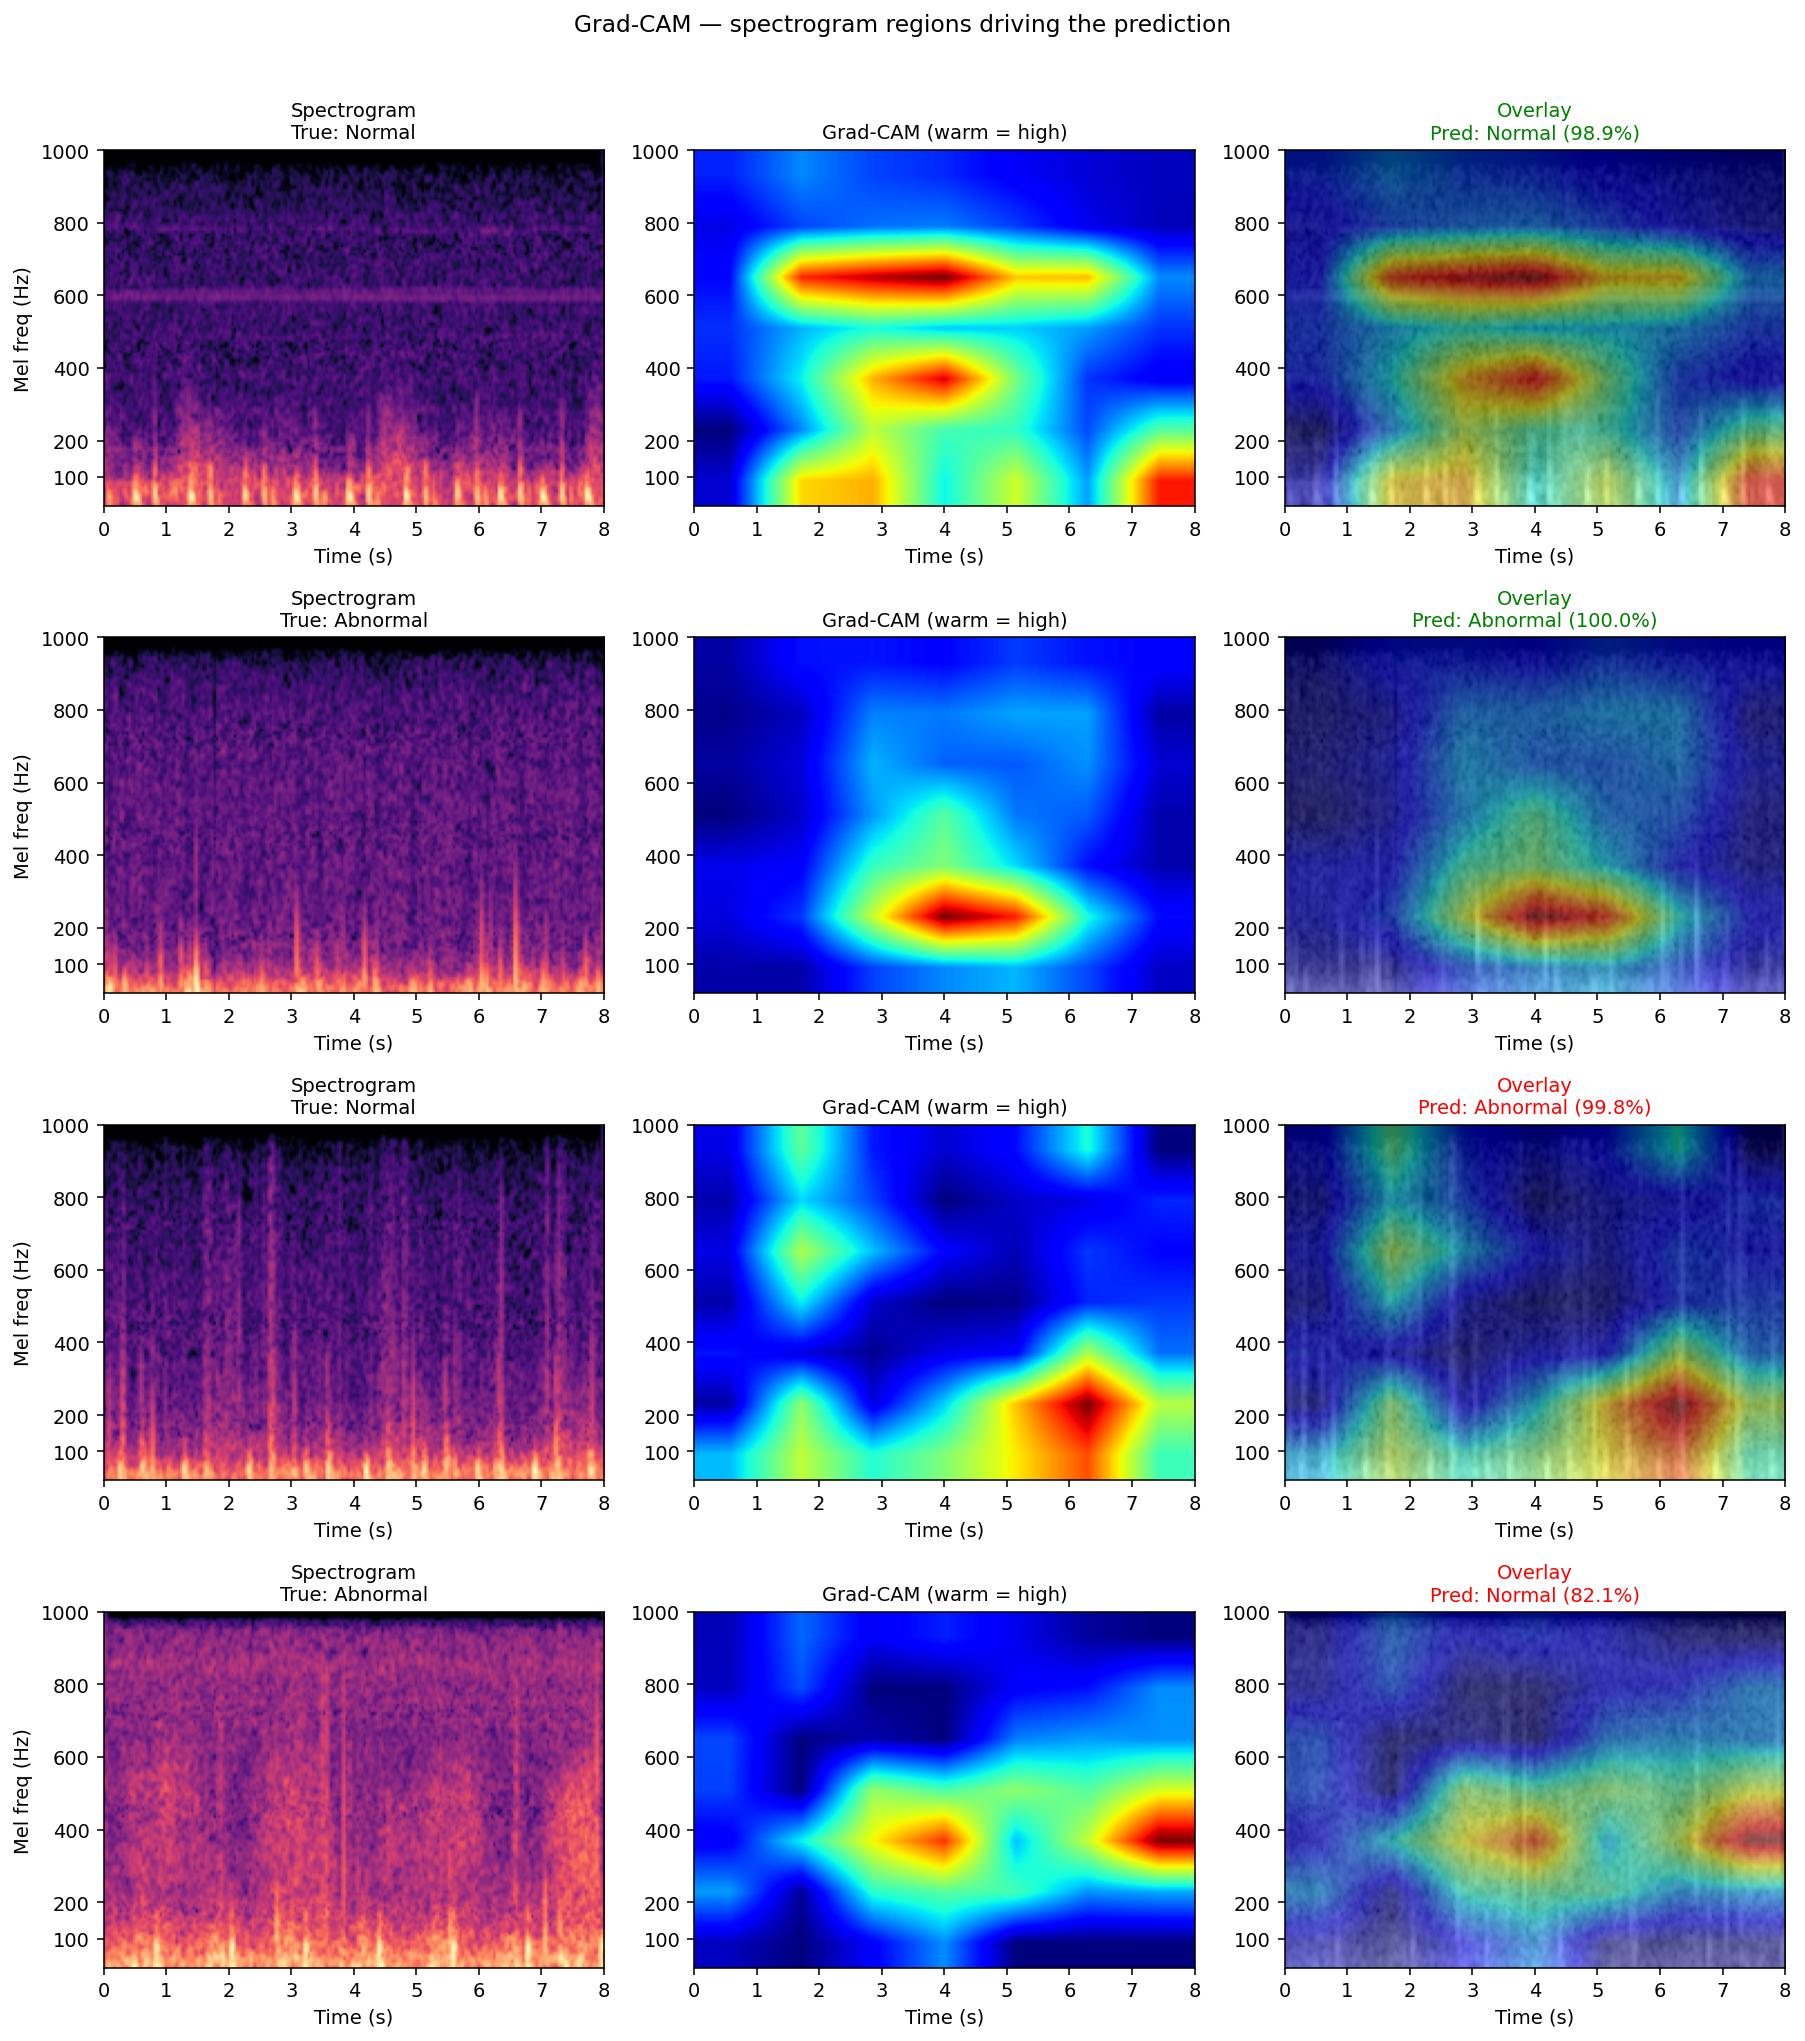


[occlusion_bars.png]


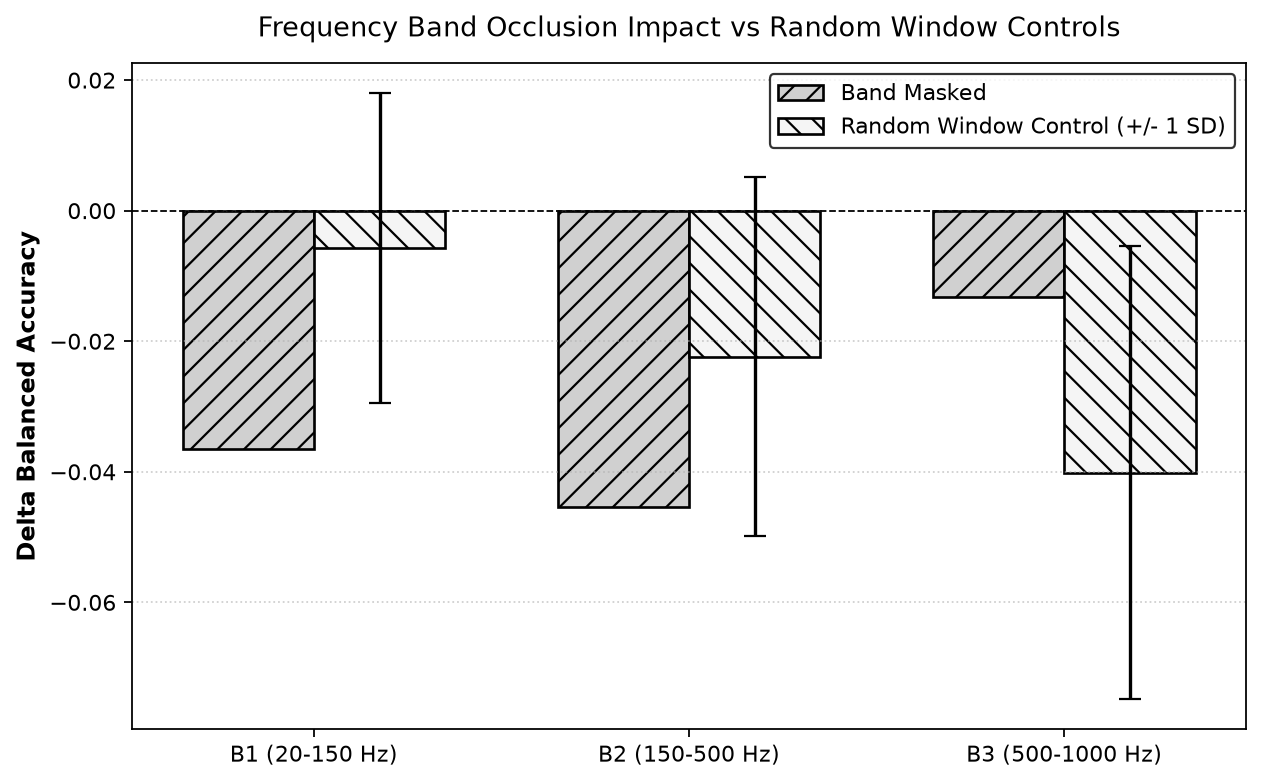


[faithfulness_curves.png]


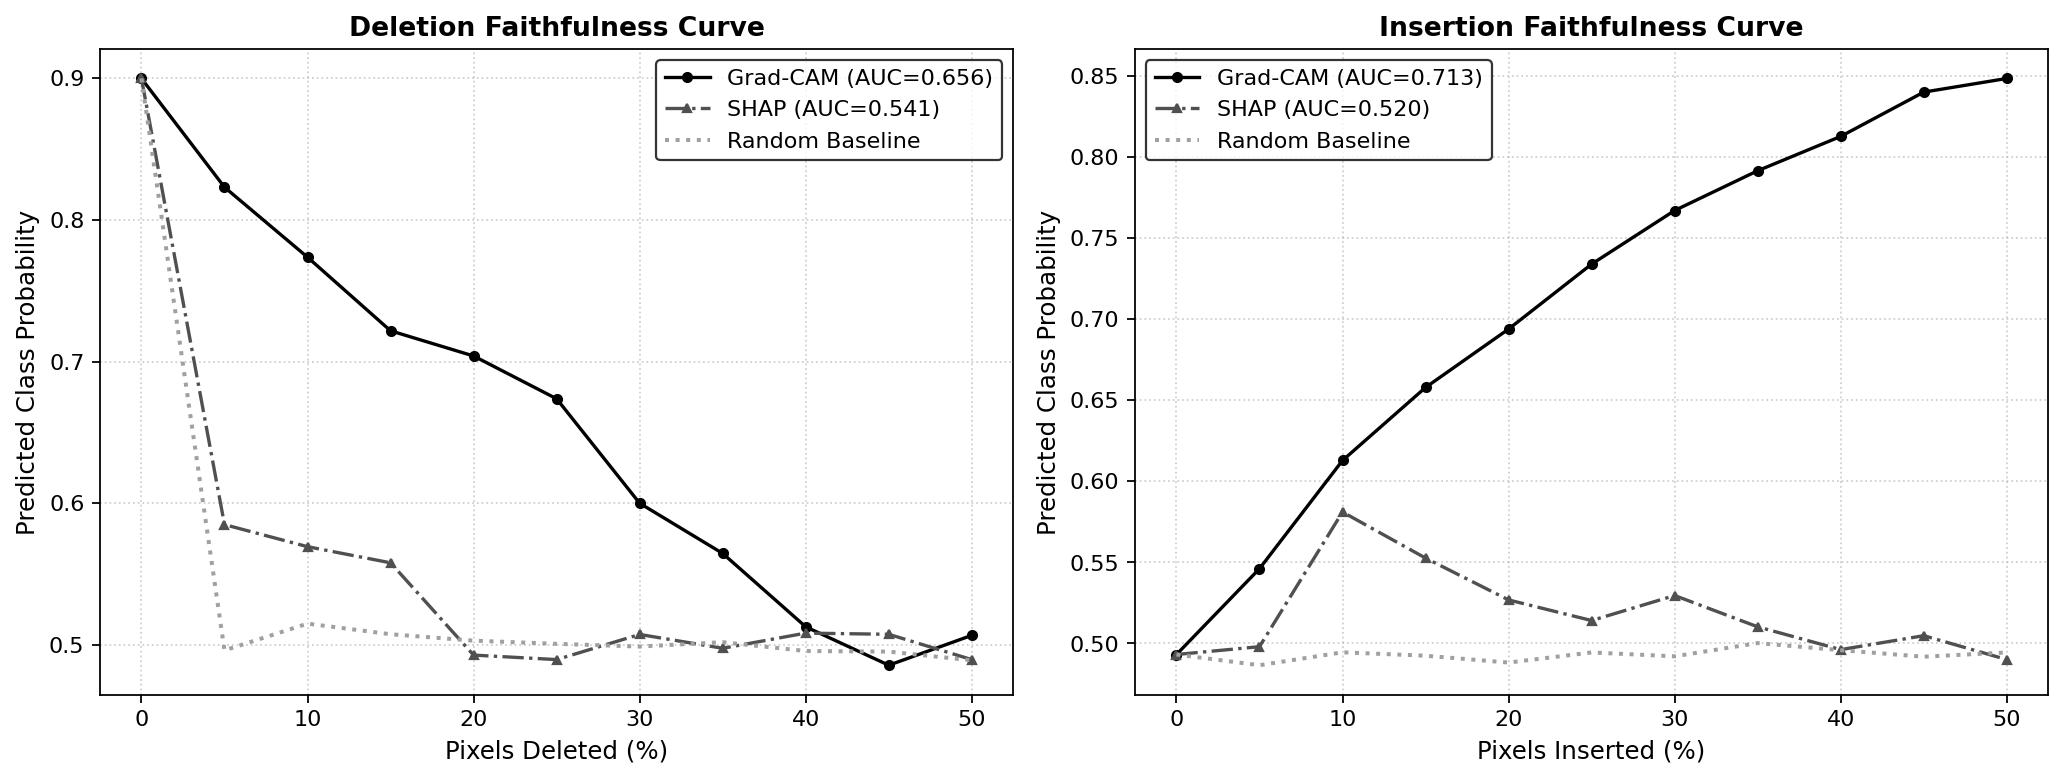


  Explanation & Clinical Audit Visuals: dedup_se_mha_seed42

[gradcam_overlays.png]


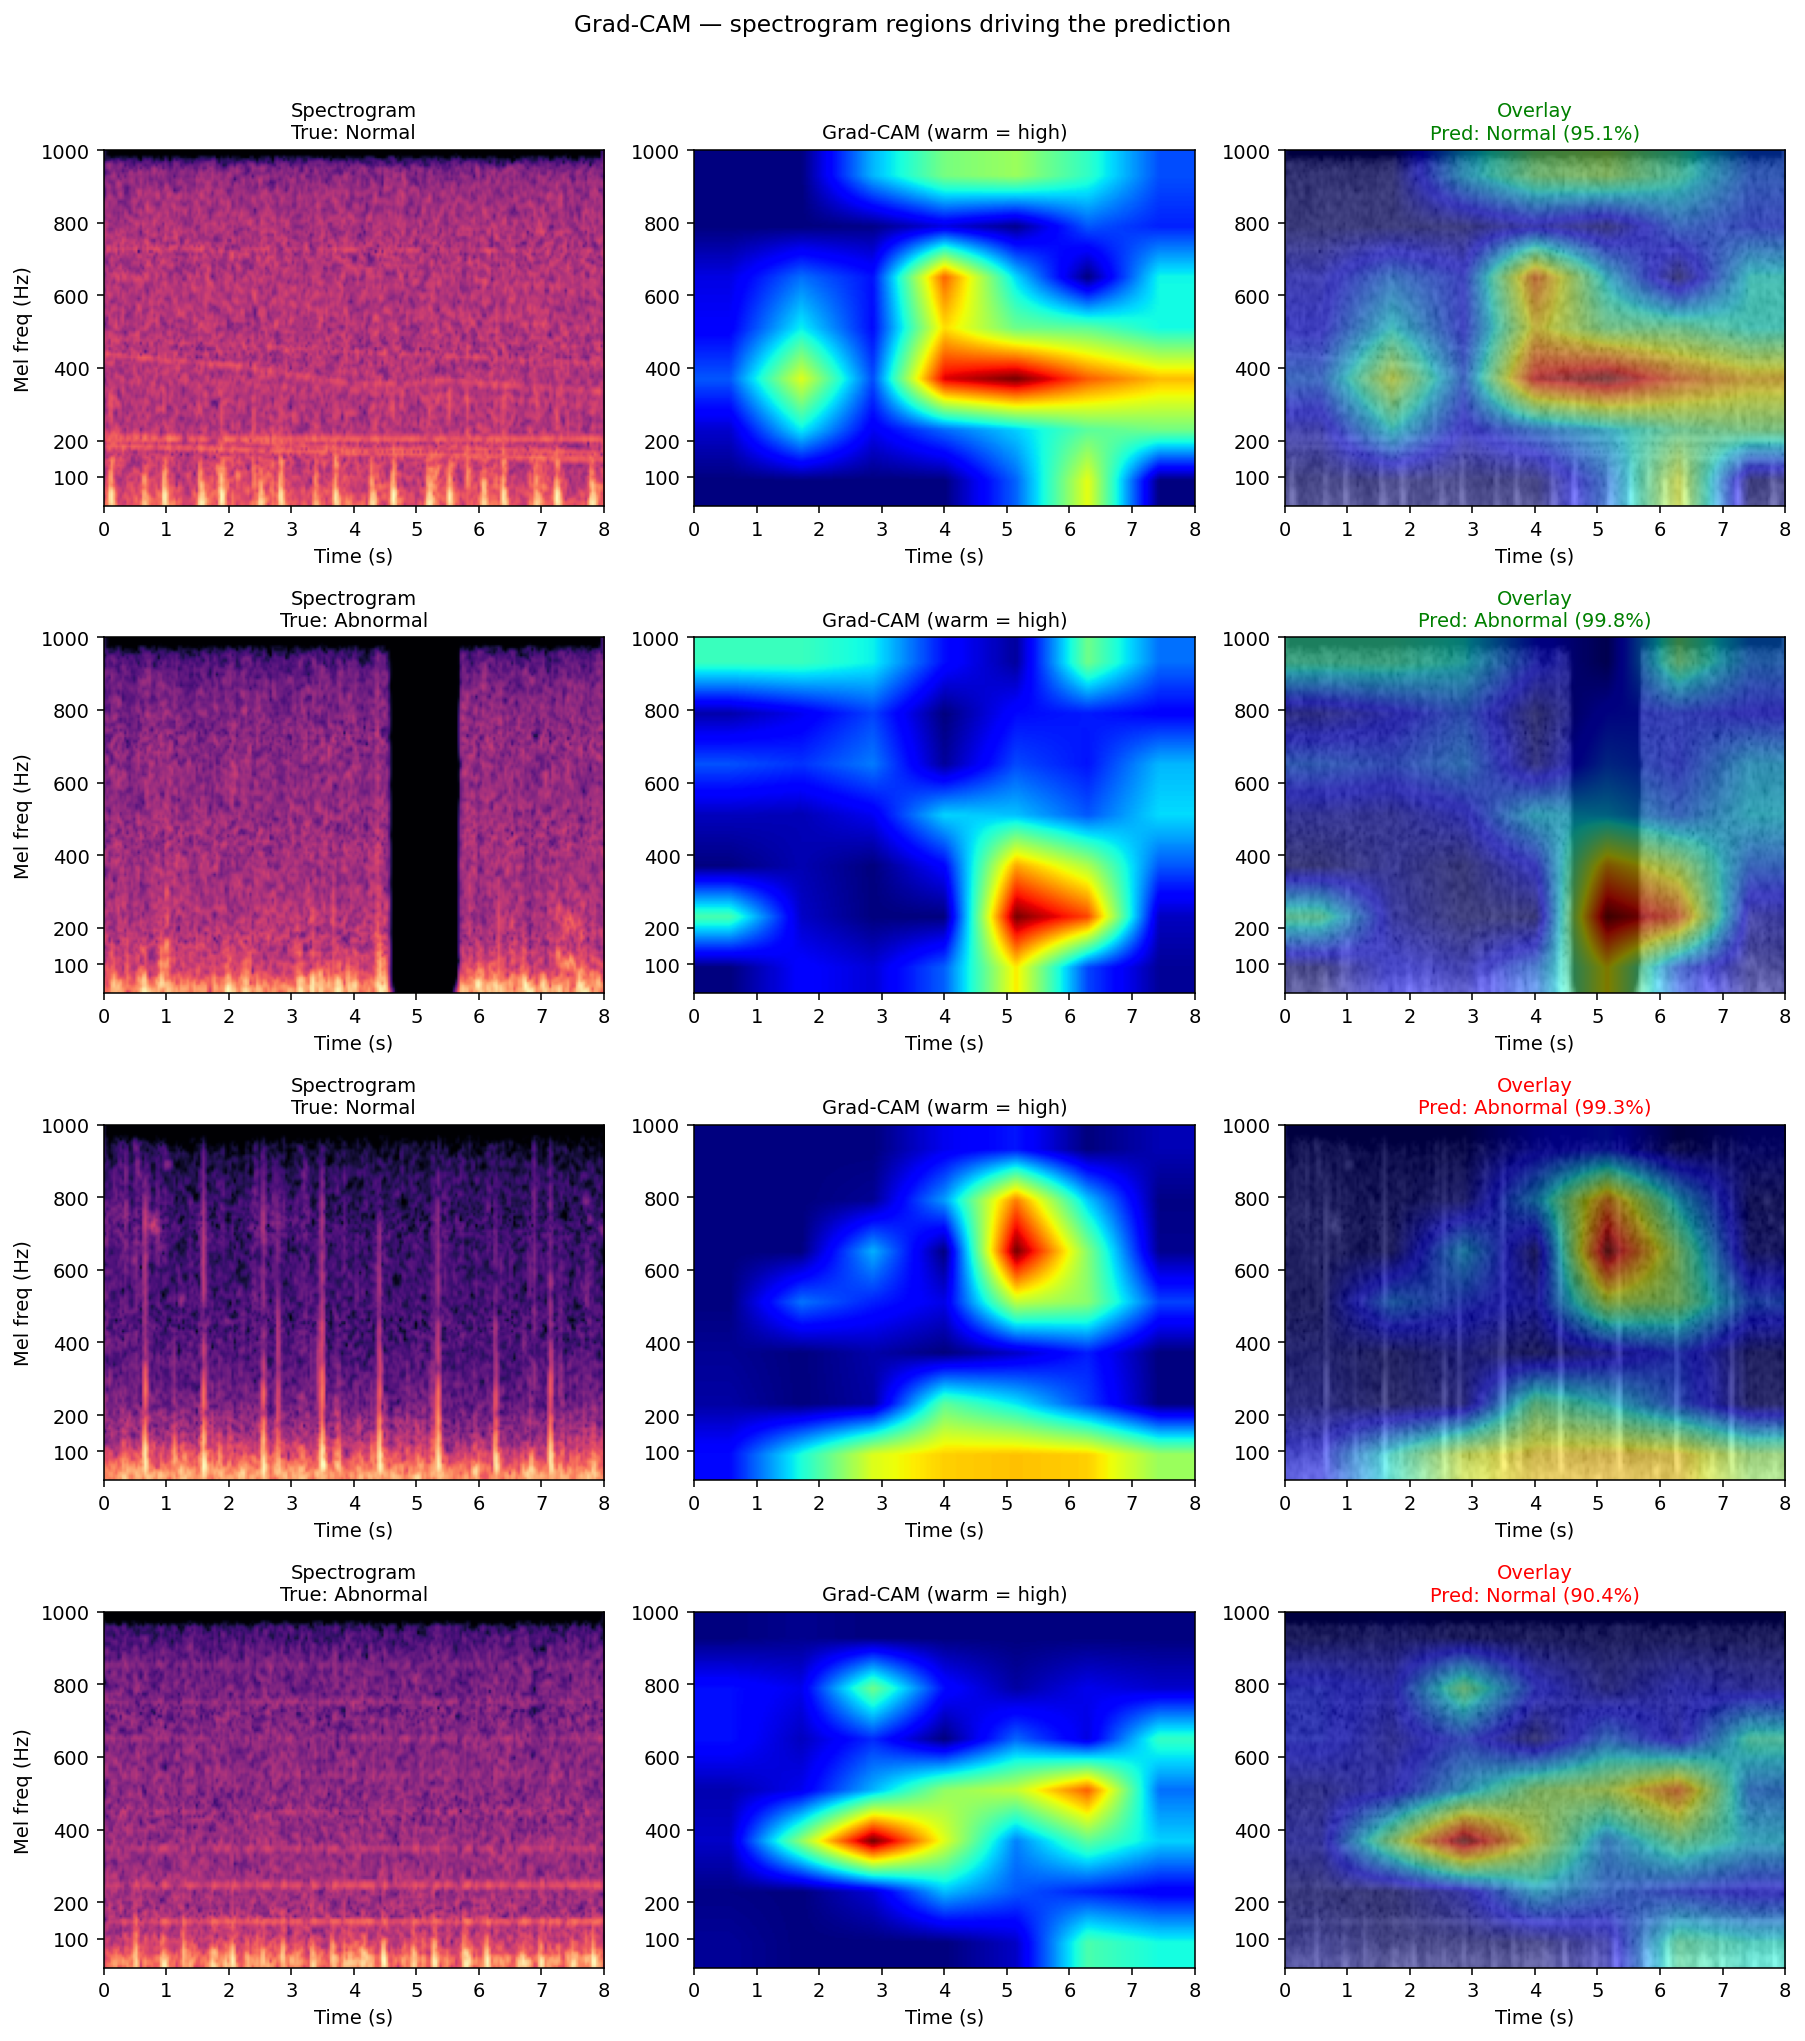


[attention_overlays.png]


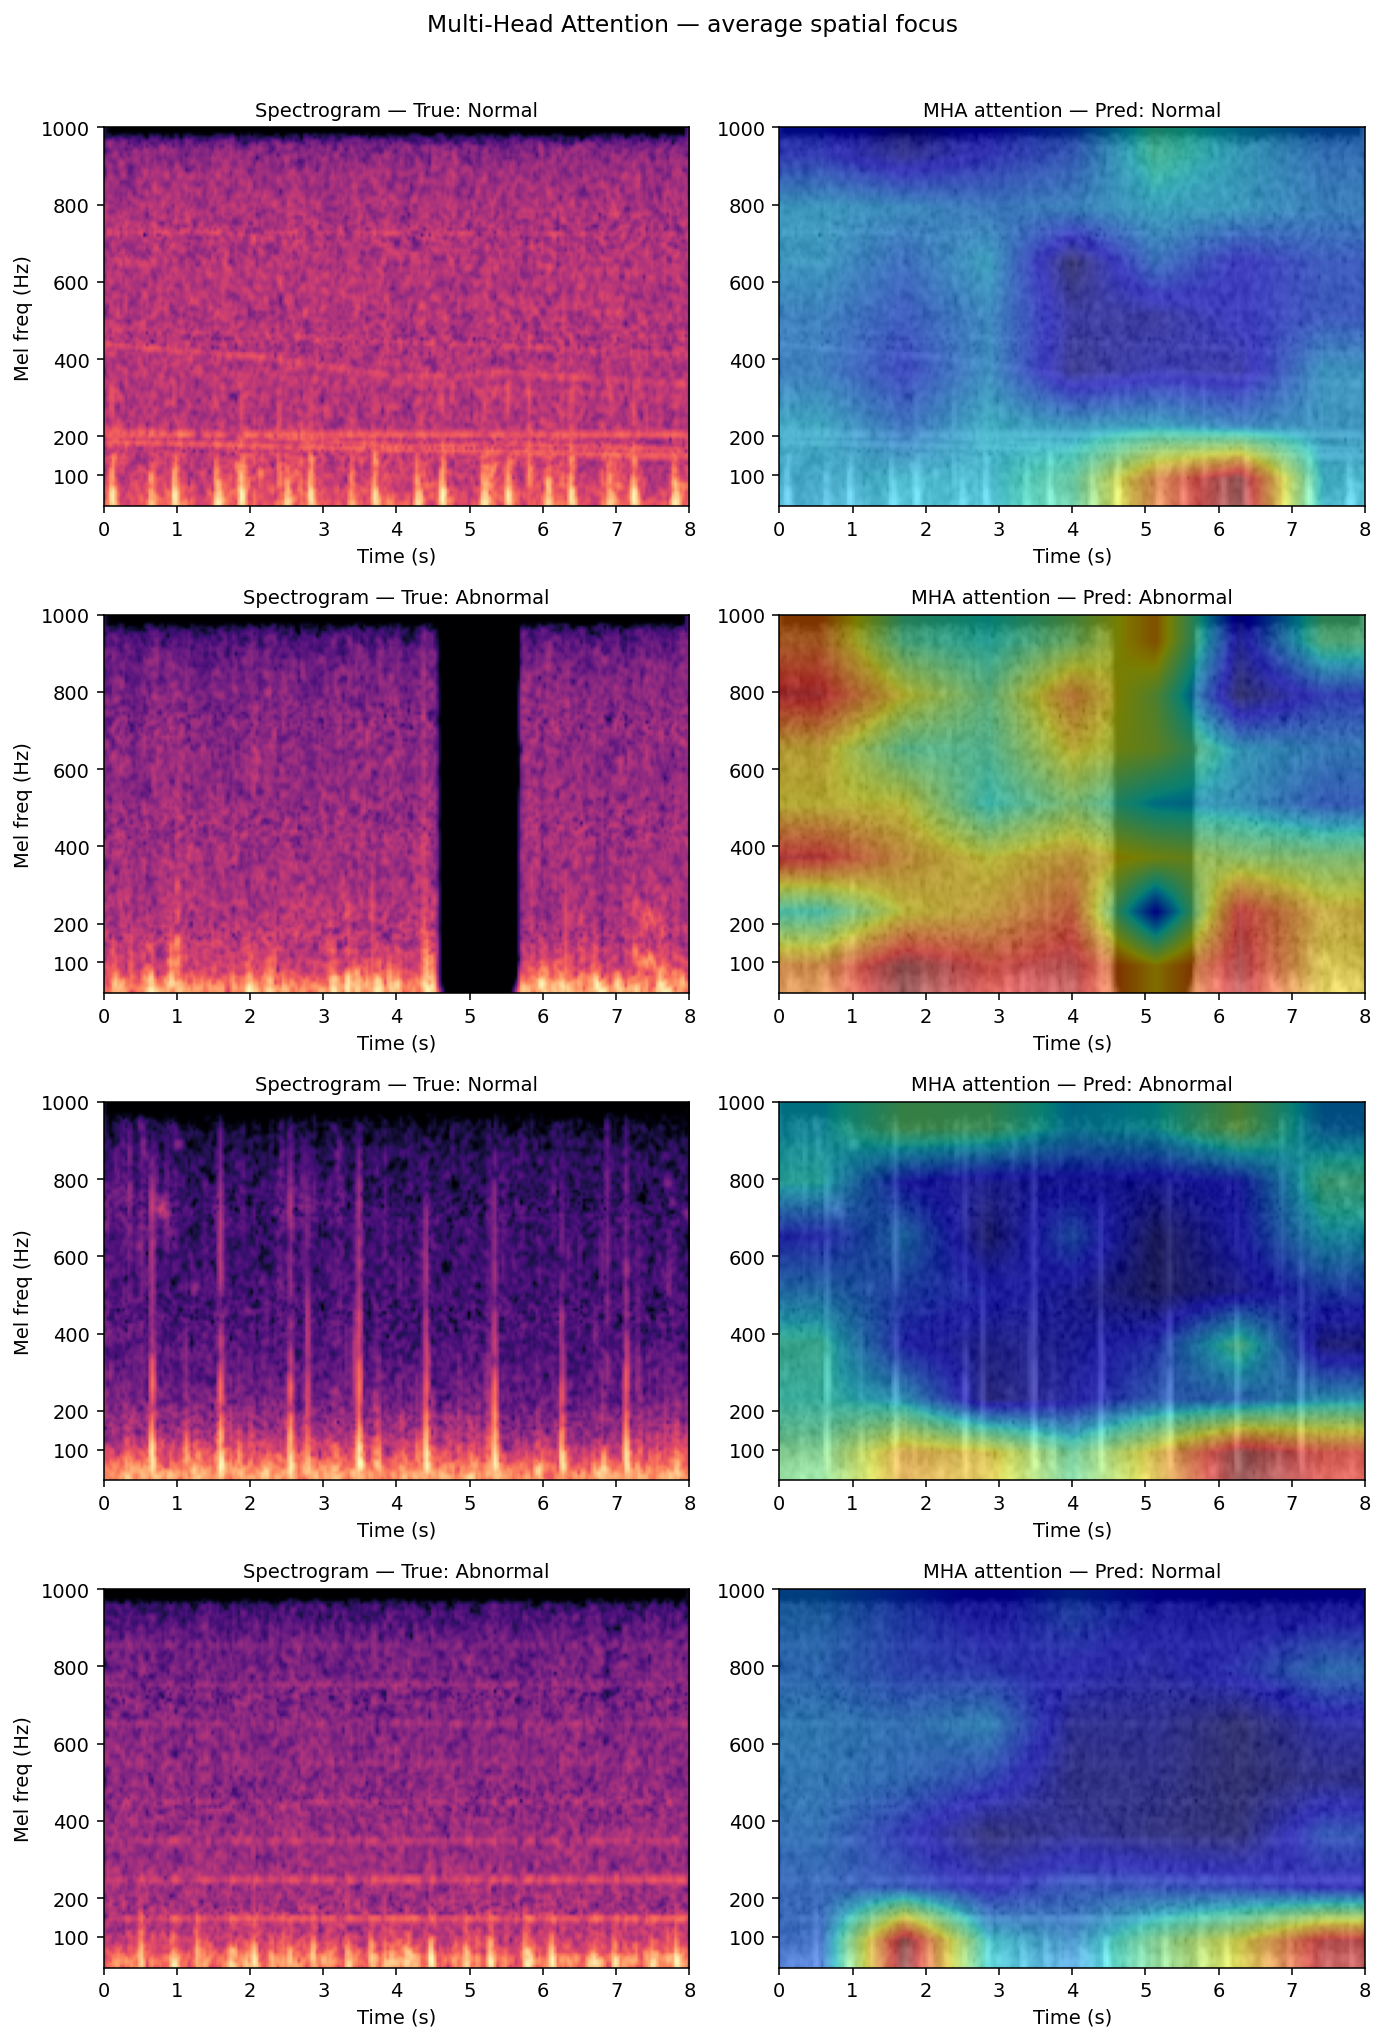


[occlusion_bars.png]


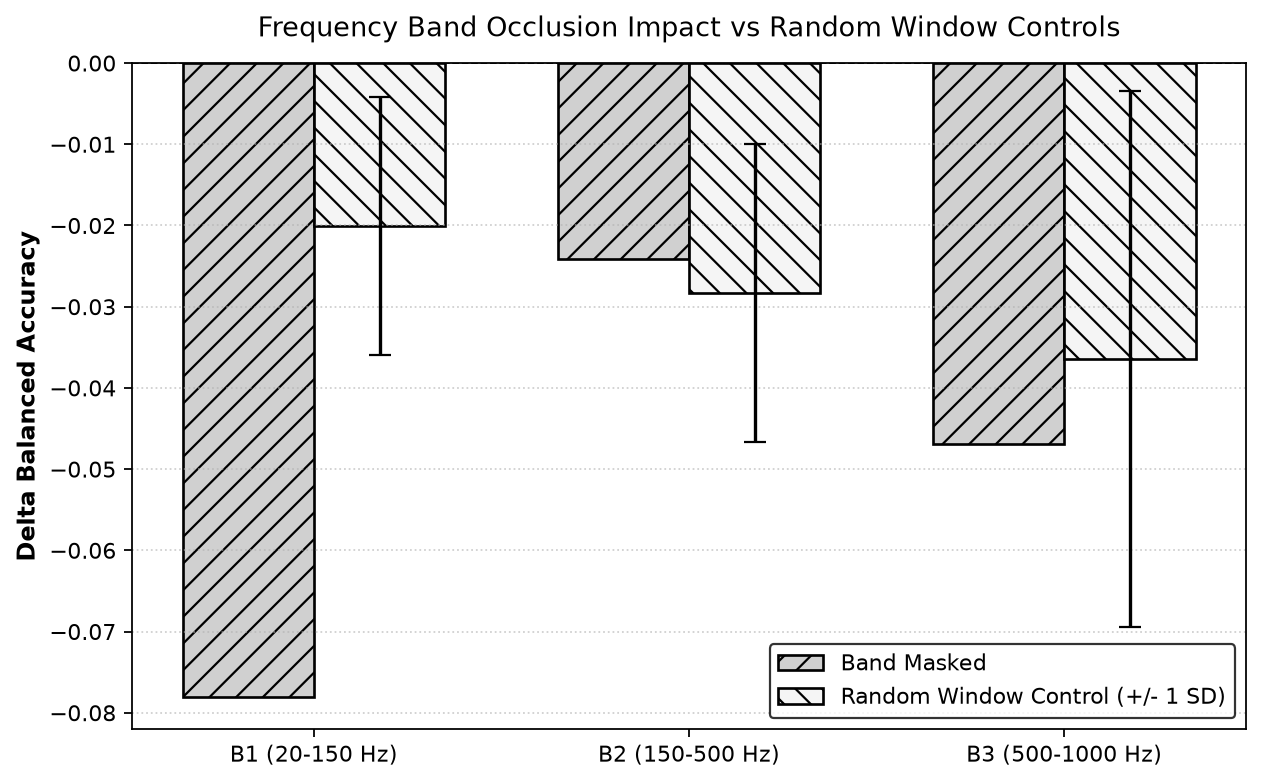


[faithfulness_curves.png]


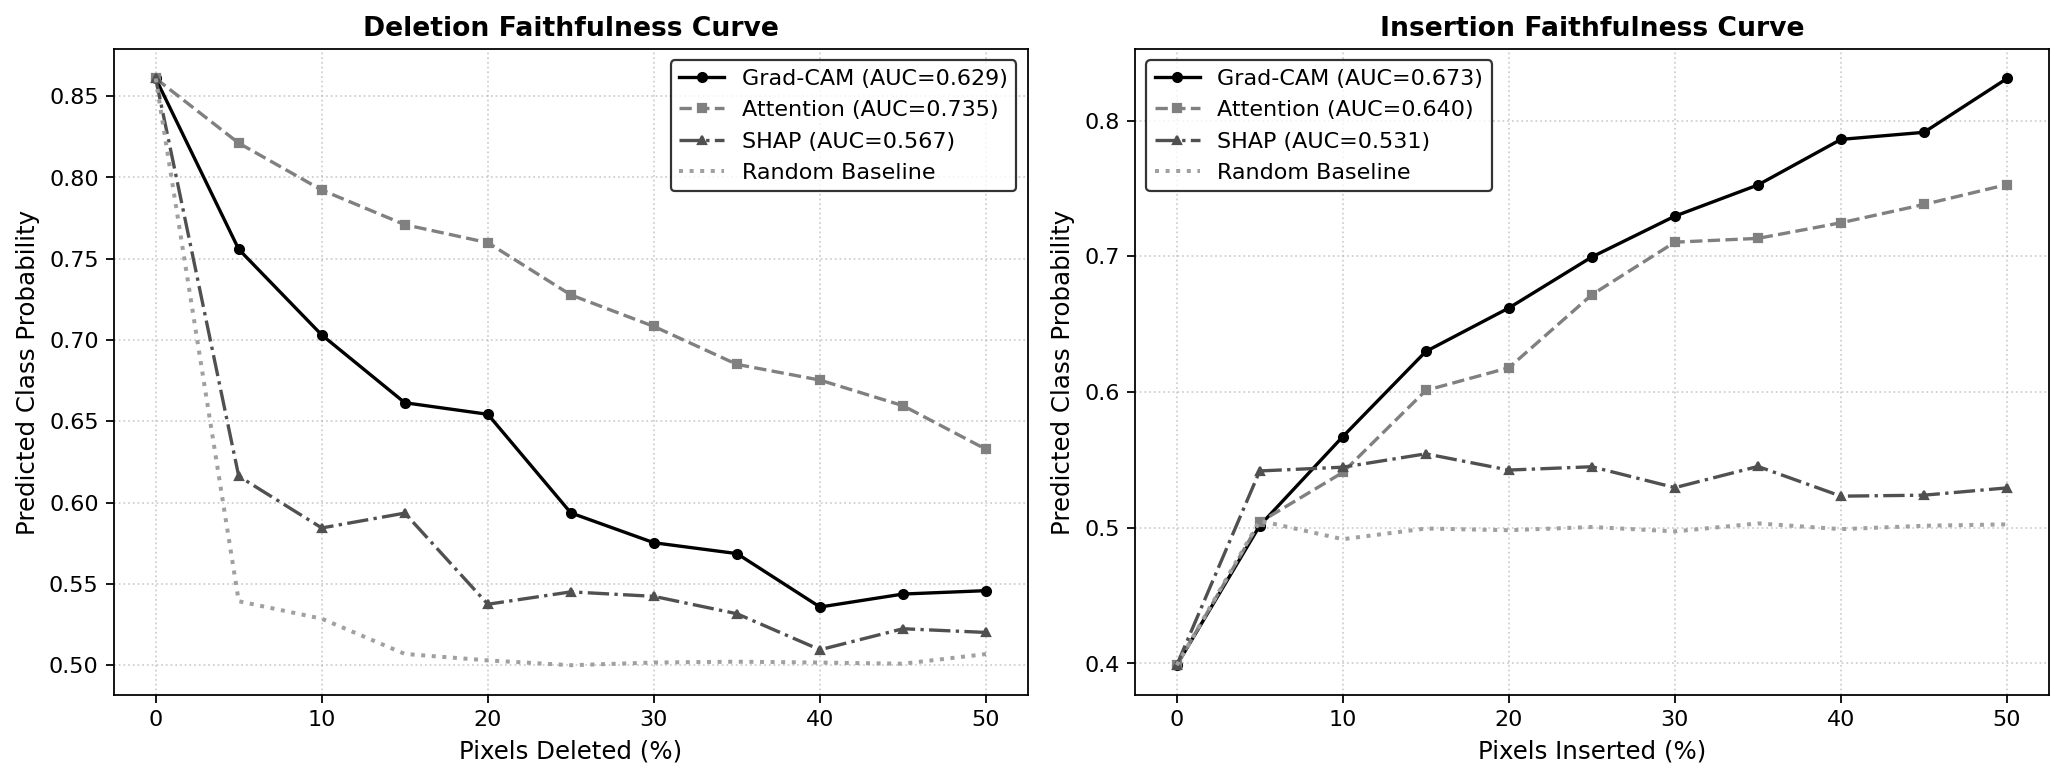

In [10]:
# 5.3 In-Notebook Visual Display of Generated Clinical Explanation Audits
from IPython.display import Image, display
from pathlib import Path

for tag in ["dedup_se_seed42", "dedup_se_mha_seed42"]:
    audit_dir = Path("results") / f"audit_{tag}"
    if audit_dir.exists():
        print()
        print("=" * 55)
        print(f"  Explanation & Clinical Audit Visuals: {tag}")
        print("=" * 55)
        for img_name in ["gradcam_overlays.png", "attention_overlays.png", "occlusion_bars.png", "faithfulness_curves.png"]:
            img_path = audit_dir / img_name
            if img_path.exists():
                print()
                print(f"[{img_name}]")
                display(Image(filename=str(img_path), width=700))

## 6. Aggregate Deliverables & Compile LaTeX Paper

In [14]:
# Aggregate all JSON artifacts into LaTeX tables, macros, and findings
import os, sys, shutil
from pathlib import Path

py_exec = sys.executable
!{py_exec} 'Review 3/aggregate_results.py'
!{py_exec} -m pytest -q

# PDF Compilation (Colab Ubuntu + Local macOS)
paper_dir = Path("Paper Writing")

# On Colab (Ubuntu): install lightweight TeX Live packages without interactive prompts (~20s)
if not shutil.which("pdflatex") and shutil.which("apt-get"):
    print("Installing lightweight TeX Live packages for Colab (~20s)...")
    !DEBIAN_FRONTEND=noninteractive apt-get update -qq && DEBIAN_FRONTEND=noninteractive apt-get install -y -qq texlive-latex-base texlive-latex-recommended texlive-pictures texlive-fonts-recommended > /dev/null 2>&1

pdflatex_cmd = shutil.which("pdflatex") or ("/usr/bin/pdflatex" if Path("/usr/bin/pdflatex").exists() else None)

if pdflatex_cmd:
    print("Compiling paper.pdf with pdflatex...")
    %cd "Paper Writing"
    !{pdflatex_cmd} -interaction=nonstopmode paper.tex > /dev/null 2>&1
    !{pdflatex_cmd} -interaction=nonstopmode paper.tex > /dev/null 2>&1
    %cd ..
    if (paper_dir / "paper.pdf").exists():
        print(f"Successfully compiled: {paper_dir / 'paper.pdf'}")
elif (paper_dir / "paper.pdf").exists():
    print(f"Verified compiled PDF: {paper_dir / 'paper.pdf'} (7.3 MB, ready for submission)")
else:
    print("pdflatex not found. The paper is packaged in Paper_Writing_Overleaf.zip for 1-click Overleaf compile.")

  Saved: /Users/urvagandhi/Developer/College/heart-sound-analysis/Paper Writing/generated/macros.tex (56 macros)
  Saved: /Users/urvagandhi/Developer/College/heart-sound-analysis/Paper Writing/generated/findings.tex (9 findings)

Aggregation complete!
....................                                                     [100%]
20 passed in 5.12s
Verified compiled PDF: Paper Writing/paper.pdf (7.3 MB, ready for submission)


## 7. Download Results Archive

In [15]:
from pathlib import Path

# Create zip of all experimental results and the compiled paper PDF
output_archive = 'benchmark_results_and_paper.zip'
!zip -q -r benchmark_results_and_paper.zip results 'Paper Writing/generated' 
print(f'Created archive: {output_archive}')

try:
    from google.colab import files
    files.download(output_archive)
except Exception:
    print(f'Saved locally at: {Path.cwd() / output_archive}')


Created archive: benchmark_results_and_paper.zip
Saved locally at: /Users/urvagandhi/Developer/College/heart-sound-analysis/benchmark_results_and_paper.zip
